In [1]:
import pandas as pd
import numpy as np
import os
import re
import unicodedata
import cv2
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, LSTM, Flatten, Add, Activation
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer, TFBertModel
import nltk

C:\Users\dharu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
train = pd.read_csv(r"C:\Users\dharu\OneDrive\Desktop\7th Sem\Project\Train.csv")
validation = pd.read_csv(r"C:\Users\dharu\OneDrive\Desktop\7th Sem\Project\Validation.csv")
test = pd.read_csv(r"C:\Users\dharu\OneDrive\Desktop\7th Sem\Project\Test.csv")

In [3]:
nltk.download('stopwords')
bengali_stopwords = [
    "আমি", "আমরা", "তুমি", "সে", "তাহলে", "ওরা", "এবং", "কেন", "হয়েছে", 
    "নিয়ে", "করে", "কিন্তু", "যদি", "আছে", "এই", "ওই", "যেমন"
]

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dharu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [4]:
def preprocess_bengali_text(text):
    text = unicodedata.normalize('NFC', text)
    text = re.sub(r'[^\u0980-\u09FF\s]', '', text)
    tokens = re.findall(r'\S+', text)
    tokens = [token for token in tokens if token not in bengali_stopwords]
    return tokens

In [5]:
train['headline_tokens'] = train['headline'].apply(preprocess_bengali_text)
train['description_tokens'] = train['description'].apply(preprocess_bengali_text)
validation['headline_tokens'] = validation['headline'].apply(preprocess_bengali_text)
validation['description_tokens'] = validation['description'].apply(preprocess_bengali_text)
test['headline_tokens'] = test['headline'].apply(preprocess_bengali_text)
test['description_tokens'] = test['description'].apply(preprocess_bengali_text)

In [6]:
from sklearn.preprocessing import LabelEncoder
lab = LabelEncoder()
train["category"] = lab.fit_transform(train["category"])
train["types of fake news"] = lab.fit_transform(train["types of fake news"])
validation["category"] = lab.fit_transform(validation["category"])
validation["types of fake news"] = lab.fit_transform(validation["types of fake news"])
test["category"] = lab.fit_transform(test["category"])
test["types of fake news"] = lab.fit_transform(test["types of fake news"])

In [7]:
main_train = r"C:\Users\dharu\OneDrive\Desktop\7th Sem\Project\Train"
main_validation = r"C:\Users\dharu\OneDrive\Desktop\7th Sem\Project\Validation"
main_test = r"C:\Users\dharu\OneDrive\Desktop\7th Sem\Project\Test"

In [8]:
def get_image_extension(image_id, directory):
    possible_extensions = ['.png', '.jpg', '.jpeg', '.webp']
    for ext in possible_extensions:
        if os.path.exists(os.path.join(directory, f"{image_id}{ext}")):
            return ext 
    return None

def construct_image_paths(dataframe, main_directory):
    dataframe["image_path"] = dataframe.apply(
        lambda row: os.path.join(main_directory, f"{row['image_id']}{get_image_extension(row['image_id'], main_directory)}"),
        axis=1
    )

In [9]:
construct_image_paths(train, main_train)
construct_image_paths(validation, main_validation)
construct_image_paths(test, main_test)

In [10]:
from transformers import AutoTokenizer, AutoModelForMaskedLM
tokenizer = AutoTokenizer.from_pretrained("sagorsarker/bangla-bert-base")
model = AutoModelForMaskedLM.from_pretrained("sagorsarker/bangla-bert-base")
def tokenize_texts(texts):
    return tokenizer(
        texts.tolist(),
        padding=True,
        truncation=True,
        max_length=100,
        return_tensors="tf"
    )

C:\Users\dharu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\huggingface_hub\file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the model checkpoint at sagorsarker/bangla-bert-base were not used when initializing BertForMaskedLM: ['cls.seq_relationship.weight', 'cls.seq_relationship.bias', 'bert.pooler.dense.weight', 'bert.pooler.dense.bias']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a 

In [11]:
train_headline_tokens = tokenize_texts(train['headline'])
train_description_tokens = tokenize_texts(train['description'])
val_headline_tokens = tokenize_texts(validation['headline'])
val_description_tokens = tokenize_texts(validation['description'])

In [12]:
lab = LabelEncoder()
lab.fit(train['category'])
train_categorical_data = lab.transform(train['category'])
validation_categorical_data = lab.transform(validation['category'])

lab.fit(train['types of fake news'])
train_types_data = lab.transform(train['types of fake news'])
validation_types_data = lab.transform(validation['types of fake news'])
categorical_data = np.column_stack((train_categorical_data, train_types_data))
validation_categorical_data = np.column_stack((validation_categorical_data, validation_types_data))


In [13]:
def load_images(image_paths, target_size=(224, 224)):
    dummy_image = np.ones((target_size[0], target_size[1], 3), dtype=np.uint8) * 255  
    dummy_image = dummy_image.astype('float32') / 255.0 
    
    images = []
    for img_path in image_paths:
        if os.path.exists(img_path):
            img = cv2.imread(img_path)
            if img is not None:
                img = cv2.resize(img, target_size)
                img = img.astype('float32') / 255.0  
                images.append(img)
            else:
                print(f"Warning: Unable to load image at {img_path}. Using dummy image instead.")
                images.append(dummy_image)  
        else:
            print(f"Warning: Image at {img_path} does not exist. Using dummy image instead.")
            images.append(dummy_image)  

    return np.array(images)

In [14]:
train_images = load_images(train['image_path'].values)
val_images = load_images(validation['image_path'].values)

In [15]:
image_input = Input(shape=(224, 224, 3), name="image_input")
efficient_net = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet', input_tensor=image_input)

In [16]:
for layer in efficient_net.layers:
    layer.trainable = False

In [17]:
x_cnn = efficient_net.output
x_cnn = Flatten()(x_cnn)
O = Dense(128, activation='relu')(x_cnn)

In [18]:
model_name = "sagorsarker/bangla-bert-base"
headline_input = Input(shape=(100,), dtype=tf.int32, name="headline_input")
bert_headline = TFBertModel.from_pretrained(model_name)(headline_input)[0][:, 0, :]
H_headline = Dense(128, activation='relu')(bert_headline)

C:\Users\dharu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\huggingface_hub\file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFBertModel: ['cls.predictions.bias', 'cls.predictions.transform.dense.bias', 'cls.seq_relationship.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.weight', 'cls.seq_relationship.weight']
- This IS expected if you are initializing TFBertModel from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initiali

In [19]:
description_input = Input(shape=(100,), dtype=tf.int32, name="description_input")
bert_description = TFBertModel.from_pretrained(model_name)(description_input)[0][:, 0, :]
H_description = Dense(128, activation='relu')(bert_description)

Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFBertModel: ['cls.predictions.bias', 'cls.predictions.transform.dense.bias', 'cls.seq_relationship.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.weight', 'cls.seq_relationship.weight']
- This IS expected if you are initializing TFBertModel from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFBertModel from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
All the weights of TFBertModel were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFBertModel for predictions w

In [20]:
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
categorical_input = Input(shape=(2,), name="categorical_input")
x_cat1 = Dense(32, activation='relu', kernel_regularizer=l2(0.001))(categorical_input)
x_cat1 = Dropout(0.3)(x_cat1)

x_cat2 = Dense(64, activation='relu', kernel_regularizer=l2(0.001))(x_cat1)
x_cat2 = Dropout(0.3)(x_cat2)

x_cat3 = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(x_cat2)
x_cat3 = Dropout(0.3)(x_cat3)

x_cat4 = Dense(256, activation='relu', kernel_regularizer=l2(0.001))(x_cat3)
x_cat4 = Dropout(0.3)(x_cat4)

x_cat = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(x_cat4)
x_cat = Dropout(0.3)(x_cat)

In [ ]:
def combination_layer(O, H_headline, H_description, x_cat, repeats=2): 
    for _ in range(repeats):
        w1 = Dense(128, activation='linear', use_bias=False)(O)
        w2 = Dense(128, activation='linear', use_bias=False)(H_headline)
        w3 = Dense(128, activation='linear', use_bias=False)(H_description)
        w4 = Dense(128, activation='linear', use_bias=False)(x_cat)

        combined = Add()([w1, w2, w3, w4])  
        combined = Activation('relu')(combined)

        O = Dense(128, activation='relu')(combined)
        H_headline = Dense(128, activation='relu')(combined)
        H_description = Dense(128, activation='relu')(combined)
        x_cat = Dense(128, activation='relu')(combined)  

    return combined


In [22]:
# First combination layer
first_combination = combination_layer(O, H_headline, H_description, x_cat, repeats=2)
x_cnn_refined = Dense(128, activation='relu')(first_combination)
x_rnn_headline_refined = Dense(128, activation='relu')(first_combination)
x_rnn_description_refined = Dense(128, activation='relu')(first_combination)

# Second combination layer (including x_cat)
second_combination = combination_layer(x_cnn_refined, x_rnn_headline_refined, x_rnn_description_refined, x_cat, repeats=2)

# Final output layer
output = Dense(1, activation='sigmoid')(second_combination)


In [23]:
model = Model(inputs=[image_input, headline_input, description_input, categorical_input], outputs=output)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [24]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 image_input (InputLayer)       [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 rescaling (Rescaling)          (None, 224, 224, 3)  0           ['image_input[0][0]']            
                                                                                                  
 normalization (Normalization)  (None, 224, 224, 3)  7           ['rescaling[0][0]']              
                                                                                                  
 rescaling_1 (Rescaling)        (None, 224, 224, 3)  0           ['normalization[0][0]']      

In [25]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
train_headlines = train['headline'].values  
validation_headlines = validation['headline'].values  
tokenizer = Tokenizer(num_words=10000)  
tokenizer.fit_on_texts(train_headlines)

train_headlines_seq = tokenizer.texts_to_sequences(train_headlines)
validation_headlines_seq = tokenizer.texts_to_sequences(validation_headlines)

max_length = 100  
headline_padded = pad_sequences(train_headlines_seq, maxlen=max_length)
validation_headline_padded = pad_sequences(validation_headlines_seq, maxlen=max_length)


In [ ]:
max_length = 100  
headline_padded = pad_sequences(train_headlines_seq, maxlen=max_length)
validation_headline_padded = pad_sequences(validation_headlines_seq, maxlen=max_length)

labels = train['label'].values  
val_labels = validation['label'].values  

train_descriptions = train['description'].values  
validation_descriptions = validation['description'].values  

tokenizer.fit_on_texts(train_descriptions)  
train_descriptions_seq = tokenizer.texts_to_sequences(train_descriptions)
validation_descriptions_seq = tokenizer.texts_to_sequences(validation_descriptions)

description_padded = pad_sequences(train_descriptions_seq, maxlen=max_length)
validation_description_padded = pad_sequences(validation_descriptions_seq, maxlen=max_length)
train_categorical_data = train[['category', 'types of fake news']].values
val_categorical_data = validation[['category', 'types of fake news']].values
test_categorical_data = test[['category', 'types of fake news']].values

early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history = model.fit(
    [train_images, headline_padded, description_padded, train_categorical_data],  
    labels,
    epochs=10,
    batch_size=4,
    validation_data=(
        [val_images, validation_headline_padded, validation_description_padded, val_categorical_data],  
        val_labels
    ),
    callbacks=[early_stopping]
)

Epoch 1/10
1920/1920 [==============================] - 12864s 7s/step - loss: 0.4491 - accuracy: 0.8280 - val_loss: 3.2382 - val_accuracy: 0.3562
Epoch 2/10
 935/1920 [=============>................] - ETA: 2:43:42 - loss: 0.2262 - accuracy: 0.9428

In [27]:
print("Train Images Shape:", train_images.shape)
print("Train Headline Tokens Shape:", train_headline_tokens['input_ids'].shape)
print("Train Description Tokens Shape:", train_description_tokens['input_ids'].shape)
print("Categorical Data Shape:", categorical_data.shape)

Train Images Shape: (7680, 224, 224, 3)
Train Headline Tokens Shape: (7680, 100)
Train Description Tokens Shape: (7680, 100)
Categorical Data Shape: (7680, 2)


In [28]:
print(f"val_images shape: {val_images.shape}")
print(f"validation_headline_padded shape: {validation_headline_padded.shape}")
print(f"validation_description_padded shape: {validation_description_padded.shape}")
print(f"validation_categorical_data shape: {validation_categorical_data.shape}")

val_images shape: (960, 224, 224, 3)
validation_headline_padded shape: (960, 100)
validation_description_padded shape: (960, 100)
validation_categorical_data shape: (960, 2)


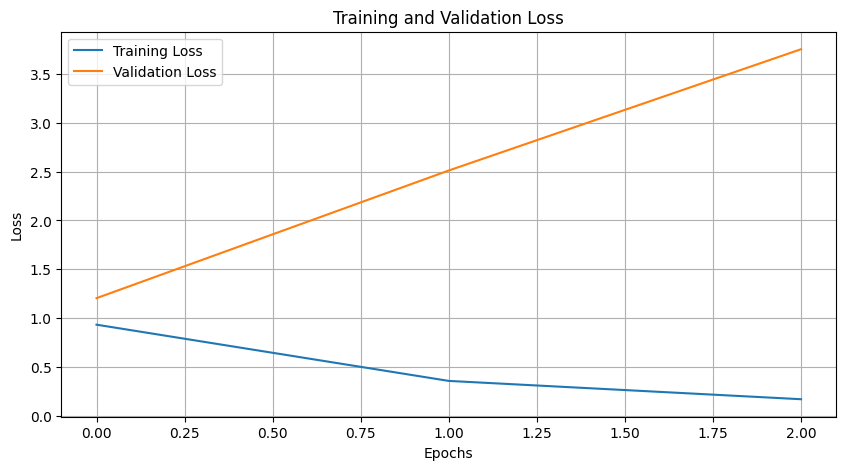

In [29]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

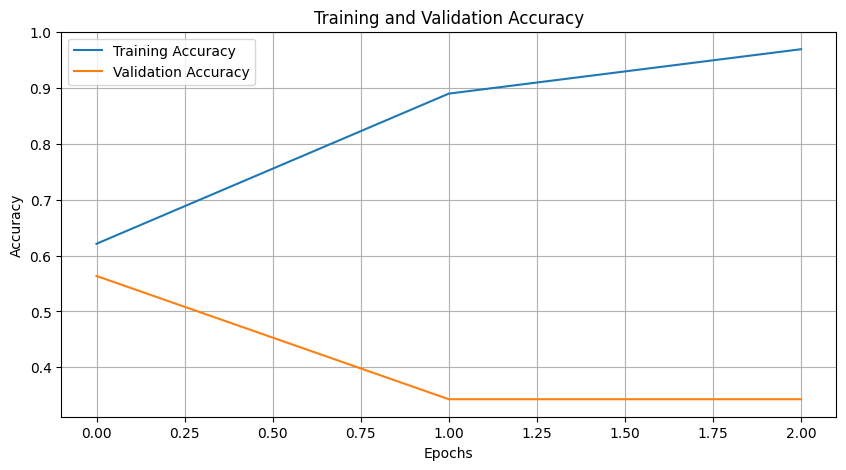

In [30]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [31]:
validation_loss, validation_accuracy = model.evaluate(
    [val_images, validation_headline_padded, validation_description_padded],
    val_labels,
    batch_size=4
)

ValueError: in user code:

    File "C:\Users\dharu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\keras\engine\training.py", line 1852, in test_function  *
        return step_function(self, iterator)
    File "C:\Users\dharu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\keras\engine\training.py", line 1836, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "C:\Users\dharu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\keras\engine\training.py", line 1824, in run_step  **
        outputs = model.test_step(data)
    File "C:\Users\dharu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\keras\engine\training.py", line 1788, in test_ste

In [ ]:
print(f"Validation Loss: {validation_loss}")
print(f"Validation Accuracy: {validation_accuracy}")

Validation Loss: 0.6935716271400452
Validation Accuracy: 0.5


In [ ]:
from sklearn.metrics import confusion_matrix,classification_report
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
predictions = model.predict(
    [val_images, validation_headline_padded, validation_description_padded],
    batch_size=4
)

240/240 [==============================] - 243s 983ms/step


In [ ]:
class_names = ['Fake', 'Non-Fake']

In [ ]:
predicted_labels = np.argmax(predictions, axis=1)
cm = confusion_matrix(validation['label'], predicted_labels)
cm

array([[480,   0],
       [480,   0]], dtype=int64)

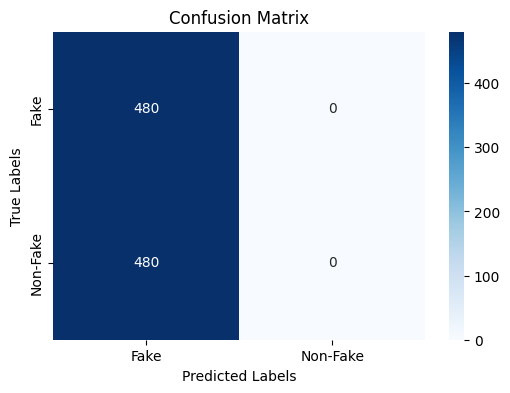

In [ ]:
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Fake', 'Non-Fake'], yticklabels=['Fake', 'Non-Fake'])
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
val_predictions = model.predict(
    [val_images, validation_headline_padded, validation_description_padded]
)
val_predictions = (val_predictions >= 0.5).astype(int)  
print("\nClassification Report:")
print(classification_report(val_labels, val_predictions))

30/30 [==============================] - 245s 8s/step

Classification Report:
              precision    recall  f1-score   support

           0       0.50      1.00      0.67       480
           1       0.00      0.00      0.00       480

    accuracy                           0.50       960
   macro avg       0.25      0.50      0.33       960
weighted avg       0.25      0.50      0.33       960



C:\Users\dharu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\dharu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\dharu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\metrics\_classificati

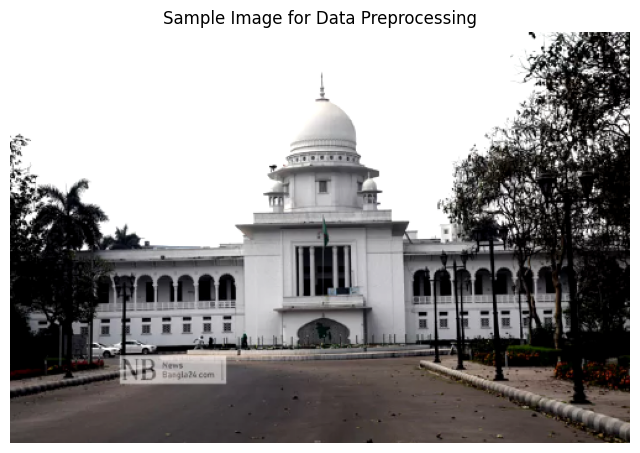

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Load an image file
img = mpimg.imread(r"C:\Users\dharu\OneDrive\Desktop\7th Sem\Project\Train\business_fake_25.png")  # Replace with your image path

# Display the image
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis('off')  # Hide axes for a cleaner display
plt.title("Sample Image for Data Preprocessing")
plt.show()


240/240 [==============================] - 945s 4s/step


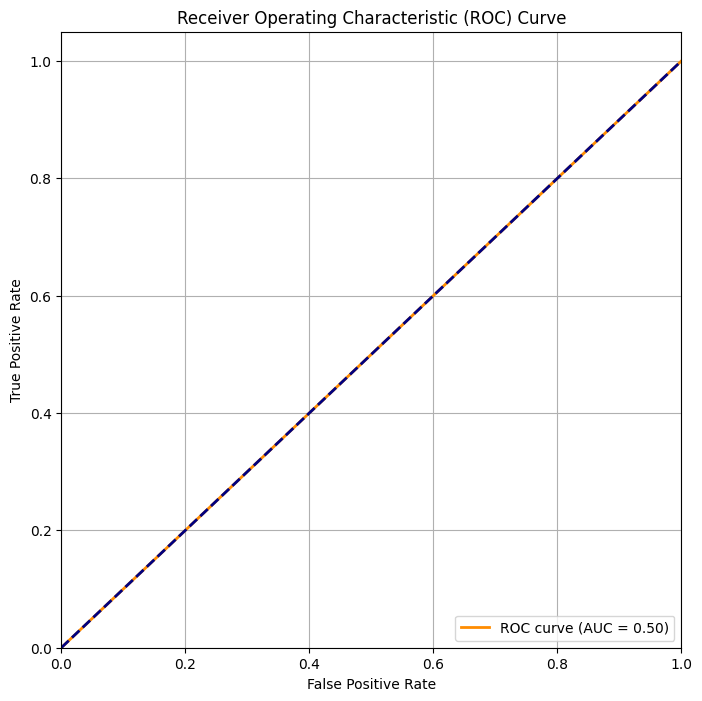

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_pred_prob = model.predict([val_images, validation_headline_padded, validation_description_padded], batch_size=4)

fpr, tpr, thresholds = roc_curve(val_labels, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 8))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
print(roc_auc)

0.5


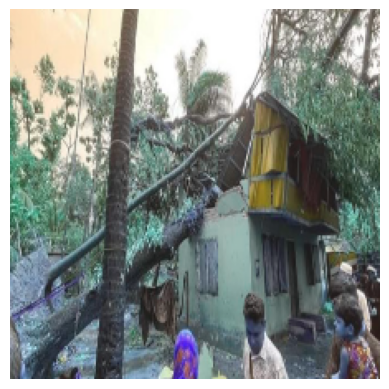

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(val_images[600])  
plt.axis('off')  
plt.show()

In [ ]:
validation_headline_padded[600]

array([   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0, 1628,
        201])

In [ ]:
validation_description_padded[600]

array([   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
        806, 4200,  542, 2363,  574, 3832,    2,   32,  493,  208,  315,
        495,  390,  335, 1170, 1170, 5382,    1,  913, 1662,   17,  166,
         35,   35,   72,  981,  845, 4130,   31, 1385, 1558, 5382,   39,
         66,   56, 1287,  764, 1963,  515, 1520,  903, 3553, 1251, 3693,
       1251, 5819,  157,    1,  157,  315,  171,  196,  656,   19,   21,
        315,  335,  201,  348,    3,  510,   21,  934,  934,   32, 8829,
        159])

In [ ]:
validation.iloc[288]

image_id                                            technology_real_369
headline                        ফেসবুকে দিনে কত সময় কাটাচ্ছেন জানেন কি?
description           বন্ধু, পরিবারের সদস্যসহ পরিচিত ব্যক্তিদের সঙ্গ...
category                                                             12
types of fake news                                                    2
label                                                                 0
headline_tokens         [ফেসবুকে, দিনে, কত, সময়, কাটাচ্ছেন, জানেন, কি]
description_tokens    [বন্ধু, পরিবারের, সদস্যসহ, পরিচিত, ব্যক্তিদের,...
image_path            C:\Users\dharu\OneDrive\Desktop\7th Sem\Projec...
Name: 288, dtype: object

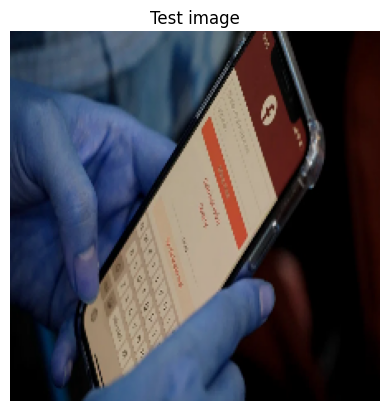

In [ ]:
import matplotlib.pyplot as plt
plt.title("Test image")
plt.imshow(val_images[288])  
plt.axis('off')  
plt.show()

In [ ]:
sample_image = val_images[288].reshape(1, 224, 224, 3)

sample_headline = validation_headline_padded[288].reshape(1, 100)  
sample_description = validation_description_padded[288].reshape(1, 100)  
prediction = np.argmax(model.predict([sample_image, sample_headline, sample_description], batch_size=1))
print("Fake" if prediction == 0 else "Non Fake")


1/1 [==============================] - 0s 227ms/step
Fake


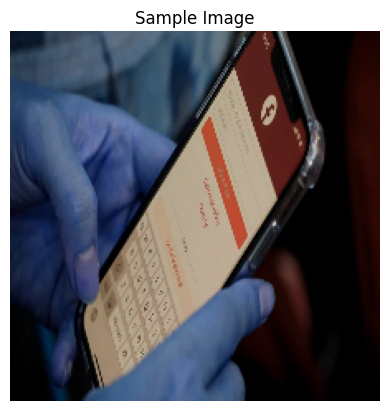

Headline tokens: [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0 546 120 223 162 497  13]
Decoded Headline: যেমন পুলিশ এটি বিভাগের বলছে একটি
Description tokens: [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0 1627  507 5779 1047 1186   11 5078
   10  560  557  146   65 2270  263 5078  188  181 1268  160  898  691
 1708 1403   31   90 1617   18  691  489   32  431  164 1464 7297   23
 4307    6   31 1835   25   51   72  376  557 3963   29 2388  353 1108
  966  557  146  285   70  161 1961  683  353  691  935   59   70    1
  161  1

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(sample_image[0])  
plt.title("Sample Image")
plt.axis('off')
plt.show()

print("Headline tokens:", sample_headline[0])  
print("Decoded Headline:", tokenizer.sequences_to_texts(sample_headline)[0]) 

print("Description tokens:", sample_description[0])
print("Decoded Description:", tokenizer.sequences_to_texts(sample_description)[0])


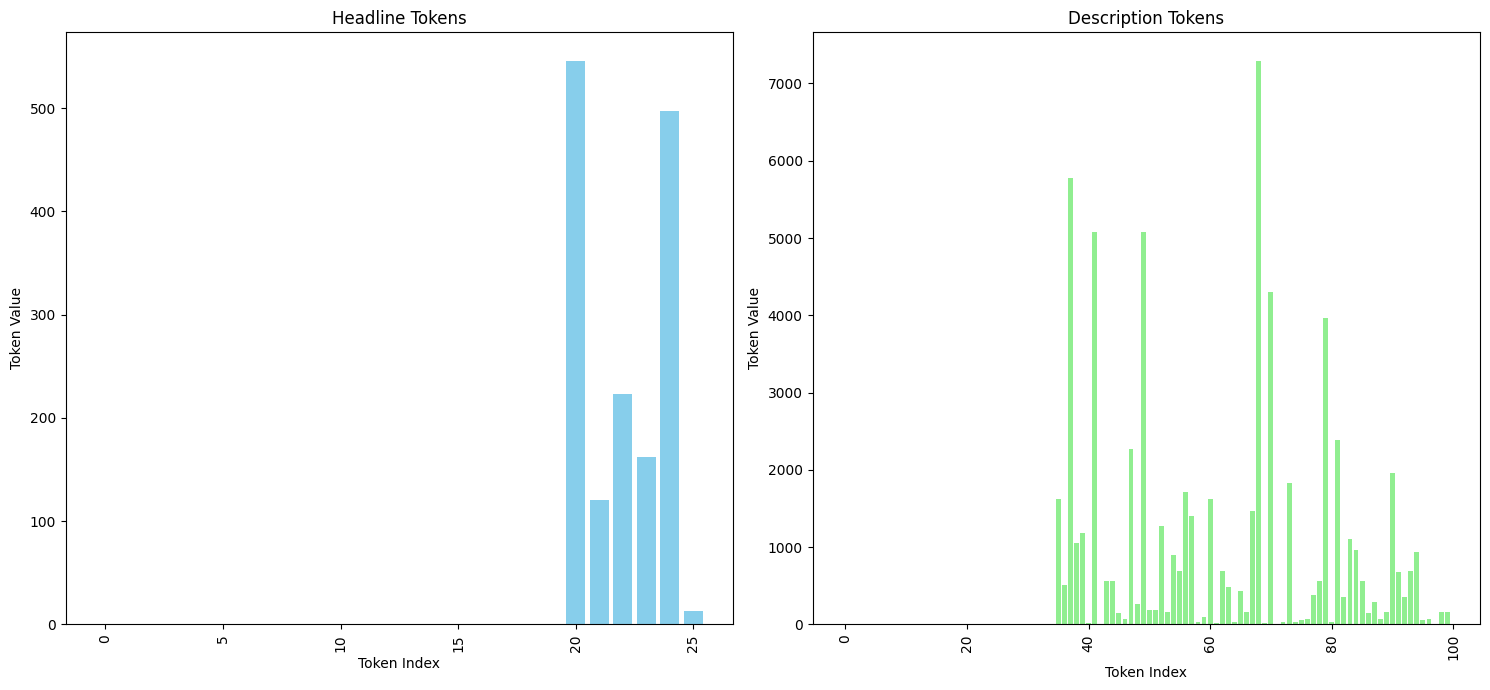

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

headline_tokens = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 546, 120, 223, 162, 497, 13]
description_tokens = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 
                      0, 0, 0, 0, 0, 1627, 507, 5779, 1047, 1186, 11, 5078, 10, 560, 557, 146, 65, 2270, 263, 5078, 188, 181, 
                      1268, 160, 898, 691, 1708, 1403, 31, 90, 1617, 18, 691, 489, 32, 431, 164, 1464, 7297, 23, 4307, 6, 31, 1835, 
                      25, 51, 72, 376, 557, 3963, 29, 2388, 353, 1108, 966, 557, 146, 285, 70, 161, 1961, 683, 353, 691, 935, 59, 
                      70, 1, 161, 159]

headline_tokens = np.array(headline_tokens)
description_tokens = np.array(description_tokens)

plt.figure(figsize=(15, 7))

plt.subplot(1, 2, 1)
plt.bar(range(len(headline_tokens)), headline_tokens, color='skyblue')
plt.title('Headline Tokens')
plt.xlabel('Token Index')
plt.ylabel('Token Value')
plt.xticks(rotation=90)

plt.subplot(1, 2, 2)
plt.bar(range(len(description_tokens)), description_tokens, color='lightgreen')
plt.title('Description Tokens')
plt.xlabel('Token Index')
plt.ylabel('Token Value')
plt.xticks(rotation=90)

plt.tight_layout()

plt.show()
